# 🛒 E-Commerce Sales Performance

**Company:** SwiftCart Retail
**Role:** Sales Operations Analyst

## 🏢 Scenario

SwiftCart Retail is looking to optimize its inventory for the next quarter. You have been assigned to identify which product categories are **“cash cows”** and which ones are underperforming based on sales performance and customer feedback.

---

## 🎯 Your Tasks

### 1️⃣ Calculate Revenue

* Create a new column called **`Total_Sales`** using the formula:

```
Total_Sales = Price × Quantity
```

* This will represent the total revenue generated per product.

---

### 2️⃣ Identify Top Performers

* Group the data by **Category**.
* Calculate total sales per category.
* Determine which category has the **highest total sales**.

---

### 3️⃣ Customer Satisfaction Analysis

* Compute the **average product rating** across all products.
* Briefly interpret what this means for overall customer satisfaction.

---

### 4️⃣ Premium Product Filtering

* Filter and list all products where:

```
Rating > 4
```

* These represent high-performing, highly rated products.

---

### 5️⃣ Visualization – Sales Performance

* Create a **Bar Chart** showing:

```
Category vs. Total Sales
```

* Include:

  * Chart title
  * Axis labels
  * Clear formatting for readability

---

### 6️⃣ Pricing Analysis

* Create a **Histogram** of product prices.
* Analyze:

  * Most common price ranges
  * Price distribution trends

---

## 📌 Expected Outcome

By completing this analysis, you should be able to:

* Identify high-revenue product categories
* Understand customer satisfaction trends
* Recognize premium-performing products
* Analyze pricing distribution
* Provide data-driven recommendations for inventory optimization

---

In [9]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/ecommerce_sales_dataset.csv")

# Calculate revenue per product/order
df["Total_Sales"] = df["Price"] * df["Quantity"]

# Review the result
print(df.head())

   Order_ID Product_Category  Price  Quantity  Customer_Rating  Total_Sales
0      1001            Books   1894         4              3.8         7576
1      1002      Electronics   2210         1              4.6         2210
2      1003         Clothing    897         2              4.2         1794
3      1004         Clothing   3890         1              2.8         3890
4      1005      Electronics   3529         3              3.6        10587


In [11]:
# Group by product category and calculate total sales using the active DataFrame
category_sales = (
    df.groupby("Product_Category", as_index=False)["Total_Sales"]
      .sum()
      .sort_values("Total_Sales", ascending=False)
)

# Show category totals
print(category_sales)

# Identify the top category
top_category = category_sales.iloc[0]
print(
    f"Top category: {top_category['Product_Category']} "
    f"with total sales of {top_category['Total_Sales']:,}"
)

  Product_Category  Total_Sales
3             Home        71874
2      Electronics        38910
1         Clothing        24963
0            Books         7576
Top category: Home with total sales of 71,874


In [13]:
# Calculate the overall average customer rating using the active DataFrame
average_rating = df["Customer_Rating"].mean()

print(f"Average customer rating: {average_rating:.2f} out of 5")

Average customer rating: 3.86 out of 5


In [16]:
# Filter products/orders with a customer rating greater than 4 using the active DataFrame
premium_products = (
    df[df["Customer_Rating"] > 4]
    .sort_values(
        by=["Customer_Rating", "Total_Sales"],
        ascending=[False, False]
    )
)

# Display the filtered records
print(premium_products.to_string(index=False))

# Count high-performing records
print(f"\nHigh-rated products/orders: {len(premium_products)}")

 Order_ID Product_Category  Price  Quantity  Customer_Rating  Total_Sales
     1020         Clothing   2759         5              5.0        13795
     1016             Home   2703         4              5.0        10812
     1008             Home   2349         4              4.8         9396
     1007             Home    697         3              4.8         2091
     1012      Electronics   1679         1              4.8         1679
     1006             Home   2228         2              4.7         4456
     1002      Electronics   2210         1              4.6         2210
     1010             Home   3080         5              4.4        15400
     1013             Home   2130         2              4.2         4260
     1003         Clothing    897         2              4.2         1794

High-rated products/orders: 10


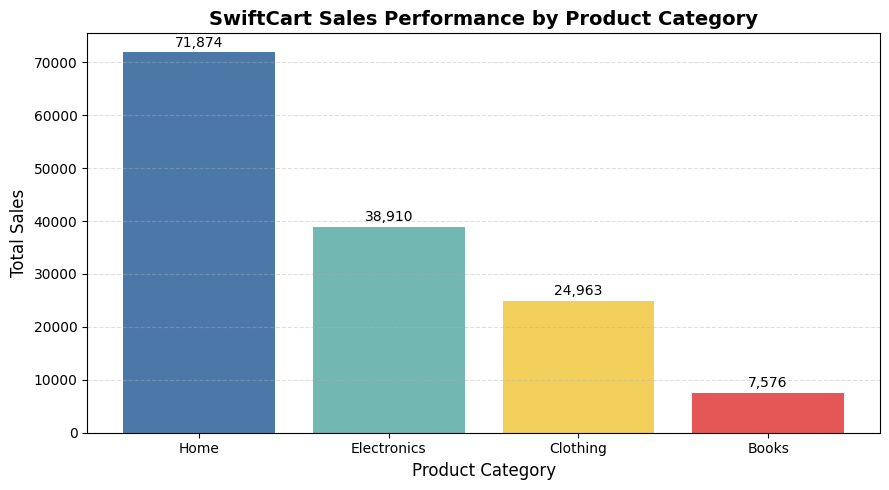

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate total sales for each product category using the active DataFrame
category_sales = (
    df.groupby("Product_Category", as_index=False)["Total_Sales"]
      .sum()
      .sort_values("Total_Sales", ascending=False)
)

# Create the bar chart
plt.figure(figsize=(9, 5))
bars = plt.bar(
    category_sales["Product_Category"],
    category_sales["Total_Sales"],
    color=["#4C78A8", "#72B7B2", "#F2CF5B", "#E45756"]
)

# Add title and axis labels
plt.title("SwiftCart Sales Performance by Product Category", fontsize=14, fontweight="bold")
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Sales", fontsize=12)

# Add sales-value labels above each bar
for bar, sales in zip(bars, category_sales["Total_Sales"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        sales + 500,
        f"{sales:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Improve readability
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

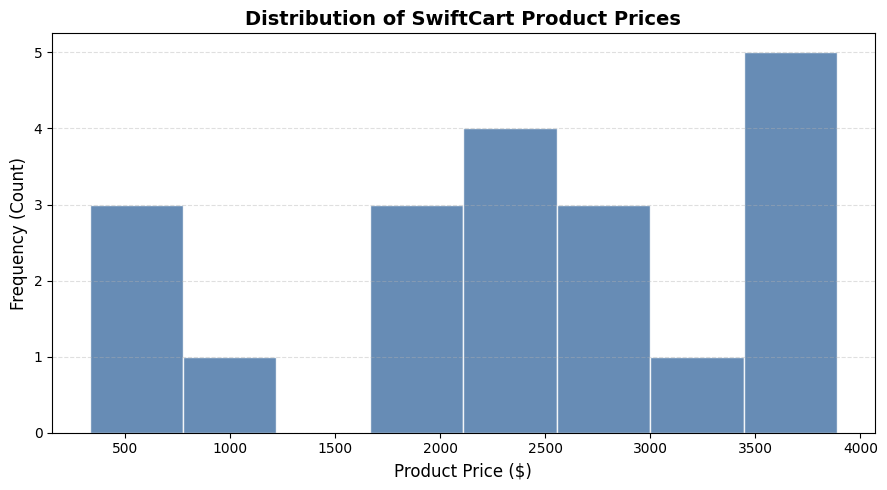

In [21]:
import matplotlib.pyplot as plt

# Create a histogram for the product prices
plt.figure(figsize=(9, 5))
plt.hist(df["Price"], bins=8, color="#4C78A8", edgecolor="white", alpha=0.85)

# Add title and axis labels
plt.title("Distribution of SwiftCart Product Prices", fontsize=14, fontweight="bold")
plt.xlabel("Product Price ($)", fontsize=12)
plt.ylabel("Frequency (Count)", fontsize=12)

# Improve layout
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

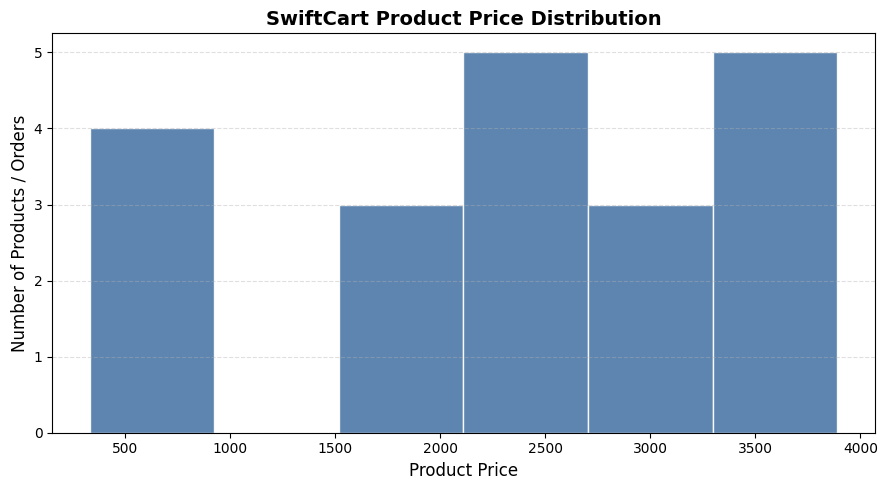

Minimum price: 331
Maximum price: 3890
Average price: 2334.05
Median price: 2288.5


In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a histogram of product prices using the active DataFrame
plt.figure(figsize=(9, 5))

plt.hist(
    df["Price"],
    bins=6,
    color="#4C78A8",
    edgecolor="white",
    alpha=0.9
)

# Add title and axis labels
plt.title(
    "SwiftCart Product Price Distribution",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Product Price", fontsize=12)
plt.ylabel("Number of Products / Orders", fontsize=12)

# Improve readability
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Optional summary statistics
print("Minimum price:", df["Price"].min())
print("Maximum price:", df["Price"].max())
print("Average price:", round(df["Price"].mean(), 2))
print("Median price:", df["Price"].median())